# 01 - Quality control

QC of the unfiltered `kb count` matrices for GSE150728 (Wilk et al. 2020). There are 13 Seq-Well PBMC libraries: 6 COVID-19 patients (one of them sampled twice) and 6 healthy donors.

Plan:
- **Part A:** work through one sample (`covid_555_2`) by hand to decide which QC metrics to use and to calibrate cutoffs against the authors' published counts.
- **Part B:** run the same steps on all 13 libraries, combine them and save.

**Inputs**
- `results/kb_count/<sample>/counts_unfiltered/` (from the Nextflow pipeline, `KB_COUNT`)
- `data/authors/<sample>_authors_totals.csv` (made by `00_authors_totals.R`)
- `assets/samplesheet.csv`

**Outputs**
- `results/qc/qc_summary.csv`: QC numbers for each sample
- `results/qc/combined_qc.h5ad`: all cells that passed QC, with raw counts kept in `layers["counts"]`

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata  

# The saved .h5ad needs AnnData >= 0.11 to read.
anndata.settings.allow_write_nullable_strings = True

RESULTS = "../results"
AUTHORS = "../data/authors"
SAMPLE  = "covid_555_2"   # sample explored in Part A

# Part A - One sample in detail (covid_555_2)

## A1. Load counts

AnnData layout: `X` is the cells x genes count matrix (sparse), `obs` has one row per cell and `var` has one row per gene.

In [2]:
path  = f"{RESULTS}/kb_count/{SAMPLE}/counts_unfiltered/"
adata = sc.read_h5ad(path + "adata.h5ad")
adata

AnnData object with n_obs × n_vars = 7106 × 62755

In [3]:
display(adata.obs.head())
display(adata.var.head())

""
barcode
AAAAAACGACCT
AAAAAACTTTGA
AAAAACCCGTGG
AAAAACGAACGC
AAAAACGATGCT


""
gene_id
ENSG00000279928.2
ENSG00000228037.1
ENSG00000142611.17
ENSG00000284616.1
ENSG00000157911.11


## A2. Add gene names

`kb` only stores Ensembl gene IDs in the matrix. The names are in a separate file, one line per gene, in the same order as the matrix columns.

Some genes don't have a name, so their line is blank. pandas skips blank lines by default, which would shift every name after the first gap onto the wrong gene without raising an error. `skip_blank_lines=False` keeps those lines in place.

In [4]:
ids   = pd.read_csv(path + "cells_x_genes.genes.txt",       header=None, skip_blank_lines=False)[0]
names = pd.read_csv(path + "cells_x_genes.genes.names.txt", header=None, skip_blank_lines=False)[0]

print(len(ids), len(names), adata.n_vars)
assert len(ids) == len(names) == adata.n_vars
assert (ids.values == adata.var_names).all(), "gene order differs from the matrix columns"

adata.var["gene_name"] = names.fillna(ids).values   # unnamed genes keep their ID as the label
adata.var.head()

62755 62755 62755


,gene_name
gene_id,
ENSG00000279928.2,DDX11L17
ENSG00000228037.1,ENSG00000228037.1
ENSG00000142611.17,PRDM16
ENSG00000284616.1,ENSG00000284616.1
ENSG00000157911.11,PEX10


In [5]:
mt_genes = adata.var[adata.var["gene_name"].str.startswith("MT-")]
print(f"Mitochondrial genes: {len(mt_genes)}")   # 37 = 13 protein-coding + 22 tRNA + 2 rRNA

adata.var[adata.var["gene_name"] == "SARS-CoV-2"]

Mitochondrial genes: 37


,gene_name
gene_id,
SARS-CoV-2,SARS-CoV-2


## A3. Per-cell QC metrics

The three metrics I'm using:
- `total_counts`: UMIs per cell, i.e. how many molecules were captured
- `n_genes_by_counts`: how many different genes were detected
- `pct_counts_mt`: % of UMIs from mitochondrial genes. When a cell is damaged, its cytoplasmic mRNA leaks out but the mitochondrial transcripts stay inside the mitochondria, so a high % usually points to a broken or dying cell.

In [6]:
adata.var["mt"] = adata.var["gene_name"].str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe()

,total_counts,n_genes_by_counts,pct_counts_mt
count,7106.000000,7106.000000,7106.000000
mean,2101.771742,1139.982269,5.773341
std,2201.976512,746.969950,3.976095
min,3.000000,3.000000,0.000000
25%,831.000000,616.000000,3.655863
50%,1343.000000,922.000000,4.855078
75%,2493.000000,1446.750000,6.705847
max,32900.000000,5992.000000,54.620123


**covid_555_2:** 7,106 barcodes. Per cell: median 1,343 UMIs, 922 genes and 4.9% mitochondrial. UMIs range from 3 to 32,900 and the mean is above the median, so the distribution is right-skewed (a few barcodes have a lot of UMIs).

## A4. Knee plot

Barcodes ranked from most to fewest UMIs, on log-log axes. What I expected: a high plateau (real cells), a bend, then a long low tail of empty wells.

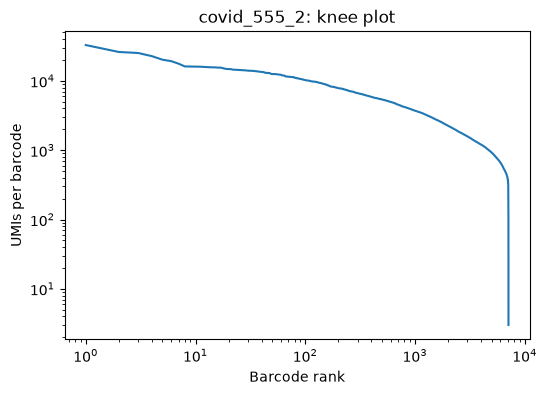

Barcodes with < 100 UMIs: 6
Barcodes with < 300 UMIs: 30
Barcodes with < 500 UMIs: 491
Barcodes with < 1000 UMIs: 2394


In [7]:
umis = np.sort(adata.obs["total_counts"].values)[::-1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(1, len(umis) + 1), umis)
ax.set_xlabel("Barcode rank")
ax.set_ylabel("UMIs per barcode")
ax.set_title(f"{SAMPLE}: knee plot")
plt.show()

for cutoff in [100, 300, 500, 1000]:
    print(f"Barcodes with < {cutoff} UMIs: {(adata.obs['total_counts'] < cutoff).sum()}")

This doesn't look like the textbook knee. There's no clear bend and almost no empty-well tail. Seq-Well has no barcode whitelist, so `kb` built its own allowlist from the data, and that step had already removed most empty-well barcodes (roughly everything under 300 UMIs). So the knee plot can't be my main cell filter here, and I filter on the per-cell metrics instead.

**Limitation:** ambient-RNA tools like SoupX estimate the background "soup" from empty barcodes, and there aren't many left. To correct for ambient RNA later, I could rerun `kb count -w NONE` to keep every barcode, or use a method that doesn't need empty barcodes.

## A5. QC metric distributions

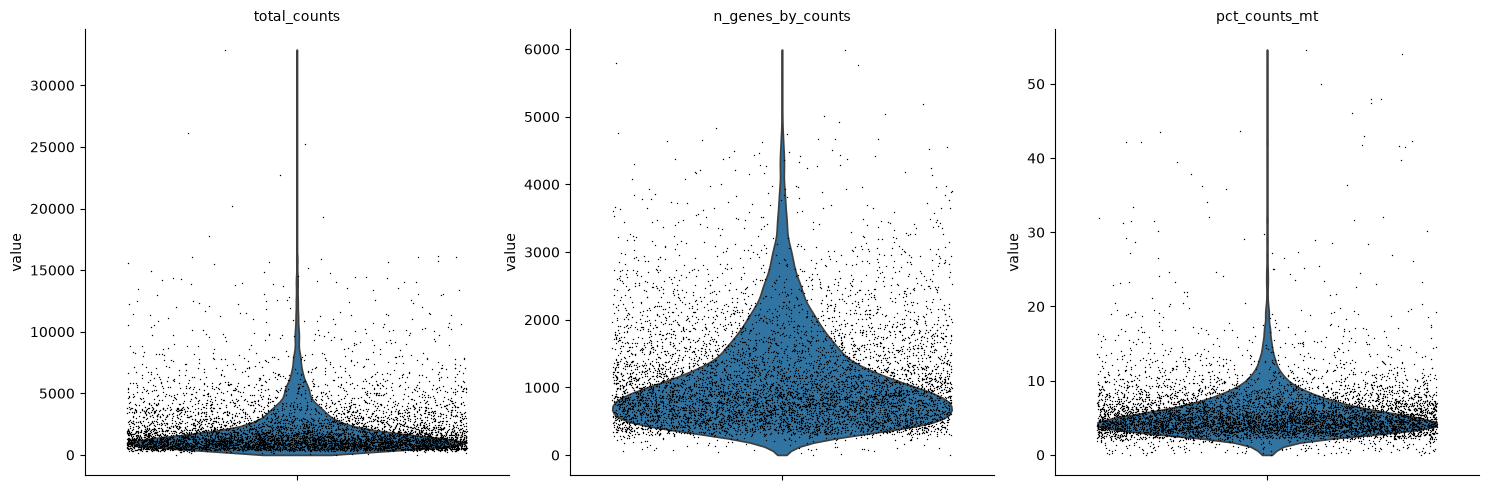

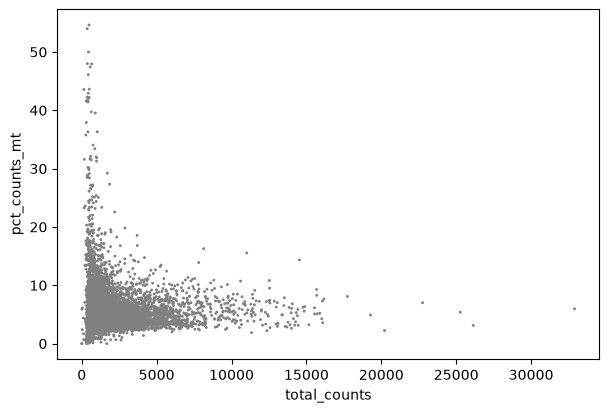

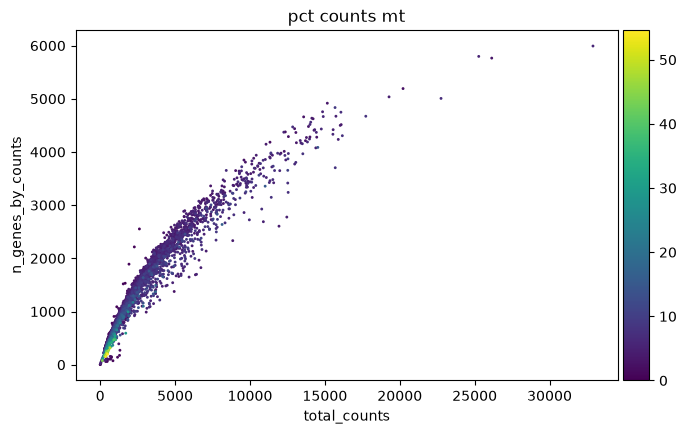

In [8]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

UMIs vs % mitochondrial makes an L shape. The high-mitochondrial barcodes are almost all at **low UMIs**, which fits with damaged cells. Healthy-looking cells sit around 3-10% mitochondrial at every UMI level. Genes go up smoothly with UMIs, and the few barcodes above 20,000 UMIs and 5,000+ genes could be doublets.

## A6. Compare with the authors' counts

The authors processed the same reads with a different pipeline (STAR + dropEst on GRCh37). Comparing UMIs per cell on the shared barcodes does two things: it checks that my pipeline finds the same cells, and it gives a conversion factor so I can use their QC cutoffs on my counts.

My barcodes:       7106
Authors' barcodes: 9663
In both:           7083
Spearman correlation:          0.980
Median ratio (ours / authors): 0.90


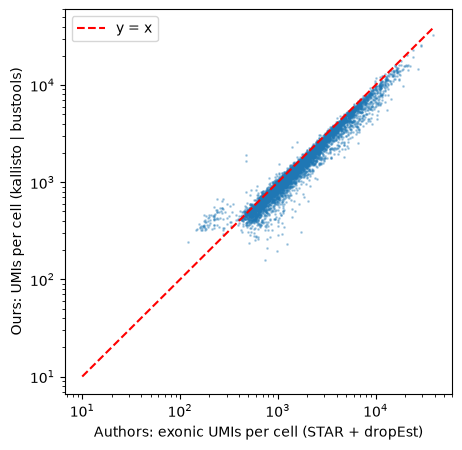

In [9]:
authors = pd.read_csv(f"{AUTHORS}/{SAMPLE}_authors_totals.csv", index_col="barcode")
merged  = adata.obs[["total_counts"]].join(authors, how="inner")

print("My barcodes:      ", adata.n_obs)
print("Authors' barcodes:", len(authors))
print("In both:          ", len(merged))

rho   = merged[["total_counts", "authors_exon"]].corr(method="spearman").iloc[0, 1]
ratio = (merged["total_counts"] / merged["authors_exon"]).median()
print(f"Spearman correlation:          {rho:.3f}")
print(f"Median ratio (ours / authors): {ratio:.2f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.loglog(merged["authors_exon"], merged["total_counts"], ".", markersize=2, alpha=0.3)
ax.plot([10, 40000], [10, 40000], "r--", label="y = x")
ax.set_xlabel("Authors: exonic UMIs per cell (STAR + dropEst)")
ax.set_ylabel("Ours: UMIs per cell (kallisto | bustools)")
ax.legend()
plt.show()

7,083 of my 7,106 barcodes (99.7%) are also in their matrix. Spearman ρ = 0.98, and I count about 10% fewer UMIs per cell than they do (ratio 0.90).

This also explains the low pseudoalignment rate from the counting step (31.8% for this sample). 27.7% of the authors' UMIs are intronic. My index only has spliced transcripts and the D-list rejects intronic reads, so those reads were never going to be counted. The low rate comes from the library itself, not from lost signal in the cells.

## A7. Cell filters

The paper's filters: 1,000-15,000 UMIs, ≤ 20% mitochondrial, cells with > 20% rRNA removed, and cells with > 75 genes per 100 UMIs removed (likely multiplets).

UMI cutoffs depend on the counting pipeline, so I can't reuse their numbers as they are. I multiply them by this sample's ratio, which applies the same standard on my scale.

In [10]:
min_umi, max_umi, max_mt = 1000 * ratio, 15000 * ratio, 20

low_umi  = adata.obs["total_counts"] < min_umi
high_umi = adata.obs["total_counts"] > max_umi
high_mt  = adata.obs["pct_counts_mt"] > max_mt
fail     = low_umi | high_umi | high_mt   # a cell can fail more than one filter

print(f"Cutoffs on my scale: {min_umi:.0f}-{max_umi:.0f} UMIs, ≤ {max_mt}% MT")
print(f"Too few UMIs:   {low_umi.sum()}")
print(f"Too many UMIs:  {high_umi.sum()}")
print(f"Too much MT:    {high_mt.sum()}")
print(f"Pass all:       {(~fail).sum()} of {adata.n_obs}")

a = authors["authors_exon"]
print(f"Authors' barcodes passing their UMI filters: {((a >= 1000) & (a <= 15000)).sum()}")

Cutoffs on my scale: 903-13542 UMIs, ≤ 20% MT
Too few UMIs:   2036
Too many UMIs:  38
Too much MT:    78
Pass all:       5020 of 7106
Authors' barcodes passing their UMI filters: 5105


About 5,020 cells pass, close to the authors' 5,105 (their number is before their mitochondrial filter). The low-UMI cutoff removes the most barcodes. Most high-mitochondrial cells were already low-UMI, so those two filters overlap a lot.

## A8. Doublets (Scrublet)

Scrublet makes fake doublets by adding together random pairs of real cells, then scores each real cell by how much it looks like those fake doublets. `random_state` fixes the random part so the result is the same every run.

predicted_doublet
False    5020
Name: count, dtype: int64


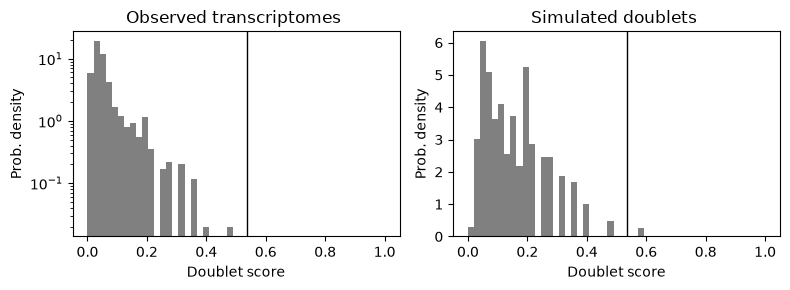

Doublet score > 0.2: 163
Doublet score > 0.25: 59
Doublet score > 0.3: 37


In [11]:
adata_f = adata[~fail].copy()   # .copy(): a separate object, not a view of `adata`
sc.pp.scrublet(adata_f, expected_doublet_rate=0.05, random_state=0)

print(adata_f.obs["predicted_doublet"].value_counts())
sc.pl.scrublet_score_distribution(adata_f)

for t in [0.2, 0.25, 0.3]:
    print(f"Doublet score > {t}: {(adata_f.obs['doublet_score'] > t).sum()}")

Scrublet called 0 doublets. The simulated doublets (right plot) should form two peaks, a low one for doublets of similar cells and a high one for doublets of different cell types, with the threshold in the gap between them. Here they form one low peak, so the automatic threshold landed at ~0.54, above every real cell's score. My guess is that the shallow sequencing and the many similar PBMC types make doublets hard to tell apart.

I'm not using Scrublet's cutoff. I keep `doublet_score` in `obs`, rely on the upper UMI cap for now, and will remove doublet clusters after annotation (marker co-expression such as CD3E + CD14, together with high scores).

## A9. rRNA check (the authors' other filter)

In [12]:
rrna = adata_f.var["gene_name"].str.match(r"^RNA(18|28|5-8|45)SN?\d")
print(adata_f.var.loc[rrna, "gene_name"].tolist())
print("rRNA UMIs in all cells:", adata_f[:, rrna].X.sum())

['RNA5-8SN3', 'RNA5-8SN1', 'RNA5-8SN2', 'RNA5-8SN4', 'RNA5-8SN5']
rRNA UMIs in all cells: 0.0


Only the 5.8S rRNA genes are annotated (18S and 28S aren't in the Ensembl 110 primary assembly), and they have 0 UMIs. That makes sense, since rRNA has no poly-A tail and poly-T capture doesn't pick it up. **So the rRNA filter isn't needed for this data.**

# Part B - All 13 samples

## B1. Load every sample

The Part A loading steps wrapped in one function. The `assert` repeats the gene-order check for every sample. I add the sample name in front of each barcode because the 12-letter barcodes are random, so the same one can show up in two samples.

In [13]:
samples = pd.read_csv("../assets/samplesheet.csv")

def load_sample(row):
    """Load one sample's kb count output and add gene names, QC metrics and sample information."""
    path = f"{RESULTS}/kb_count/{row['sample']}/counts_unfiltered/"
    ad = sc.read_h5ad(path + "adata.h5ad")

    # Gene names, with the order check
    ids   = pd.read_csv(path + "cells_x_genes.genes.txt",       header=None, skip_blank_lines=False)[0]
    names = pd.read_csv(path + "cells_x_genes.genes.names.txt", header=None, skip_blank_lines=False)[0]
    assert len(ids) == len(names) == ad.n_vars, f"Gene count mismatch in {row['sample']}"
    assert (ids.values == ad.var_names).all(),  f"Gene order mismatch in {row['sample']}"
    ad.var["gene_name"] = names.fillna(ids).values

    # QC metrics
    ad.var["mt"] = ad.var["gene_name"].str.startswith("MT-")
    sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

    # Sample information on every cell
    for col in ["sample", "donor", "condition"]:
        ad.obs[col] = row[col]

    # Make barcodes unique across samples
    ad.obs_names = row["sample"] + "_" + ad.obs_names
    return ad

In [14]:
# Test on the sample already explored by hand: should give 7,106 x 62,755
test = load_sample(samples[samples["sample"] == SAMPLE].iloc[0])
assert test.shape == adata.shape
print(test)

AnnData object with n_obs × n_vars = 7106 × 62755
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition'
    var: 'gene_name', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


In [15]:
adatas = {row["sample"]: load_sample(row) for _, row in samples.iterrows()}

summary = pd.DataFrame({
    s: {
        "barcodes":      ad.n_obs,
        "median_umis":   ad.obs["total_counts"].median(),
        "median_genes":  ad.obs["n_genes_by_counts"].median(),
        "median_pct_mt": round(ad.obs["pct_counts_mt"].median(), 1),
        "virus_umis":    ad[:, ad.var["gene_name"] == "SARS-CoV-2"].X.sum(),
    }
    for s, ad in adatas.items()
}).T
summary

,barcodes,median_umis,median_genes,median_pct_mt,virus_umis
covid_555_1,12788.0,538.5,426.5,6.4,0.0
covid_555_2,7106.0,1343.0,922.0,4.9,0.0
covid_556,5135.0,660.0,502.0,6.7,0.0
covid_557,13039.0,1105.0,762.0,5.5,0.0
covid_558,15514.0,441.0,343.0,8.7,0.0
covid_559,4626.0,951.0,636.0,10.8,0.0
covid_561,6860.0,899.5,608.0,8.9,0.0
HIP002,7865.0,492.0,393.0,6.9,0.0
HIP015,3601.0,1458.0,900.0,8.3,0.0
HIP023,5182.0,1581.0,949.5,9.0,0.0


- **SARS-CoV-2 UMIs = 0 in all 13 samples.** Same as the paper ("No SARS-CoV-2 reads were aligned"): no viral RNA in circulating PBMCs, and the healthy donors work as a negative control.
- The unfiltered medians can't be compared between samples. Samples with more barcodes have lower medians (HIP045: 16,955 barcodes, median 340) because the extra low-count background barcodes pull the median down. This is why I filter per sample.

## B2. Per-sample QC

For each sample: compare with the authors' counts, convert their cutoffs with that sample's ratio, filter, and score doublets. Scrublet runs **within each sample**, since doublets can only form between cells on the same array.

In [16]:
results  = []
filtered = {}

for s, ad in adatas.items():
    # 1. Authors' totals, with barcodes renamed to match mine (sample_ prefix)
    auth = pd.read_csv(f"{AUTHORS}/{s}_authors_totals.csv", index_col="barcode")
    auth.index = s + "_" + auth.index

    # 2. Compare the two pipelines on shared barcodes
    m     = ad.obs[["total_counts"]].join(auth, how="inner")
    ratio = (m["total_counts"] / m["authors_exon"]).median()
    rho   = m[["total_counts", "authors_exon"]].corr(method="spearman").iloc[0, 1]

    # 3. The authors' cutoffs translated to this sample's scale
    min_umi, max_umi = 1000 * ratio, 15000 * ratio
    keep = ((ad.obs["total_counts"] >= min_umi) &
            (ad.obs["total_counts"] <= max_umi) &
            (ad.obs["pct_counts_mt"] <= 20))

    # 4. Keep passing cells; score doublets within this sample
    f = ad[keep].copy()
    sc.pp.scrublet(f, expected_doublet_rate=0.05, random_state=0)
    filtered[s] = f

    # 5. Record everything
    results.append({
        "sample":           s,
        "barcodes":         ad.n_obs,
        "matched":          len(m),
        "spearman":         round(rho, 3),
        "ratio":            round(ratio, 2),
        "min_umi":          round(min_umi),
        "max_umi":          round(max_umi),
        "cells_kept":       int(keep.sum()),
        "authors_umi_pass": int(((auth["authors_exon"] >= 1000) & (auth["authors_exon"] <= 15000)).sum()),
        "dbl_score_gt_025": int((f.obs["doublet_score"] > 0.25).sum()),
    })

qc_table = pd.DataFrame(results).set_index("sample")
qc_table

,barcodes,matched,spearman,ratio,min_umi,max_umi,cells_kept,authors_umi_pass,dbl_score_gt_025
sample,,,,,,,,,
covid_555_1,12788,12687,0.958,0.96,956,14338,3261,3490,46
covid_555_2,7106,7083,0.980,0.90,903,13542,5020,5105,59
covid_556,5135,5083,0.964,0.96,962,14425,1746,1829,12
covid_557,13039,12857,0.986,0.95,951,14264,7040,7211,109
covid_558,15514,15422,0.965,0.85,855,12823,3530,3794,63
covid_559,4626,4606,0.961,0.80,798,11972,2419,2698,52
covid_561,6860,6719,0.967,0.81,814,12205,3531,3809,11
HIP002,7865,7520,0.946,0.97,966,14485,2104,2268,48
HIP015,3601,3571,0.982,1.00,999,14978,2323,2357,56


Spearman is 0.946-0.989 for every sample and the ratios go from 0.80 to 1.00, so a single cutoff for all samples wouldn't have been right (the low-UMI cutoff is 798 for covid_559 but 999 for HIP015). I keep 88-99% as many cells as the authors' UMI filter does. **46,431 cells pass** (COVID 26,547; healthy 19,884), vs 48,829 with the authors' UMI filter.

Barcode overlap with the authors is 96-99% for every sample except HIP045 (13,687 of 16,955, about 81%). HIP045 also has the most barcodes, so my guess is the extra ones are low-count background barcodes the authors never kept. It still kept a similar share of cells after filtering (88%), so I'm leaving it in.

## B3. Combine, filter genes, save

- Cell filters were applied **per sample**, because each sample has its own quality. The gene filter is applied **after combining**, because a gene that's rare in one sample can still be common across all of them.
- I copy the raw counts into `layers["counts"]` before normalizing, since pseudobulk and scVI both need raw counts later.

In [17]:
adata_all = sc.concat(list(filtered.values()), merge="same")   # merge="same": keep var columns identical across samples
print(adata_all)
print(adata_all.obs["condition"].value_counts())

print("Genes before:", adata_all.n_vars)
sc.pp.filter_genes(adata_all, min_cells=10)   # the authors' rule: genes detected in fewer than 10 cells removed
print("Genes after: ", adata_all.n_vars)

adata_all.layers["counts"] = adata_all.X.copy()

AnnData object with n_obs × n_vars = 46431 × 62755
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet'
    var: 'gene_name', 'mt'
condition
COVID      26547
Healthy    19884
Name: count, dtype: int64
Genes before: 62755
Genes after:  40448


In [18]:
os.makedirs(f"{RESULTS}/qc", exist_ok=True)
qc_table.to_csv(f"{RESULTS}/qc/qc_summary.csv")
adata_all.write_h5ad(f"{RESULTS}/qc/combined_qc.h5ad")

## Wrap-up

- **46,431 cells kept** from 13 libraries (COVID 26,547; healthy 19,884), 40,448 genes.
- My counts agree with the authors': 99.7% of my barcodes also in theirs (covid_555_2), per-cell Spearman 0.95-0.99, and 0 SARS-CoV-2 reads, same as the paper.
- Cells were filtered with the authors' cutoffs (1,000-15,000 UMIs, ≤ 20% MT), scaled to my counts per sample.

Still to revisit:
- Doublets: Scrublet called none, so I'll look for mixed-marker clusters after annotation.
- Ambient RNA: not corrected, since few empty barcodes are left.